In [1]:
import os, glob, zipfile, shutil, subprocess
from PIL import Image

# Procura o zip no /content; só monta o Drive se não achar localmente
candidatos = glob.glob('/content/5y9wdsg2zt*.zip')
if not candidatos:
    from google.colab import drive
    drive.mount('/content/drive')
    candidatos = glob.glob('/content/drive/MyDrive/**/5y9wdsg2zt*.zip', recursive=True)

assert candidatos, 'Arquivo 5y9wdsg2zt-1.zip não encontrado! Faça upload em /content/ ou no Drive.'
ZIP = candidatos[0]
print(f'Usando: {ZIP} ({os.path.getsize(ZIP)/1e6:.1f} MB)')

shutil.rmtree('/content/data', ignore_errors=True)
os.makedirs('/content/data/imagens', exist_ok=True)
zipfile.ZipFile(ZIP).extractall('/content/data')

# Extrai o .rar direto com unar (evita o bug de 0 bytes do 7z)
RAR = '/content/data/Concrete Crack Images for Classification.rar'
subprocess.run('apt-get -qq update && apt-get -qq install -y unar', shell=True, check=True)
subprocess.run(['unar', '-q', '-f', '-o', '/content/data/imagens', RAR], check=True)

# Localiza pastas Negative / Positive
BASE = None
for raiz, pastas, _ in os.walk('/content/data/imagens'):
    nomes = {p.lower(): p for p in pastas}
    if 'negative' in nomes and 'positive' in nomes:
        BASE, NEG, POS = raiz, nomes['negative'], nomes['positive']
        break

print('BASE:', BASE)
print(f'Sem fissura ({NEG}): {len(os.listdir(f"{BASE}/{NEG}"))} imagens')
print(f'Com fissura ({POS}): {len(os.listdir(f"{BASE}/{POS}"))} imagens')

# Validação rápida de integridade
amostra = os.path.join(BASE, NEG, sorted(os.listdir(f'{BASE}/{NEG}'))[0])
print('Teste de abertura OK -> dimensões:', Image.open(amostra).size)

Usando: /content/5y9wdsg2zt-1.zip (240.8 MB)
BASE: /content/data/imagens/Concrete Crack Images for Classification
Sem fissura (Negative): 20000 imagens
Com fissura (Positive): 20000 imagens
Teste de abertura OK -> dimensões: (227, 227)


In [2]:
import tensorflow as tf, platform, subprocess

print('TensorFlow:', tf.__version__)
print('GPU disponível:', tf.config.list_physical_devices('GPU'))
print('Processador:', platform.processor())
print(subprocess.run('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader',
                     shell=True, capture_output=True, text=True).stdout.strip())

TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Processador: x86_64
Tesla T4, 15360 MiB


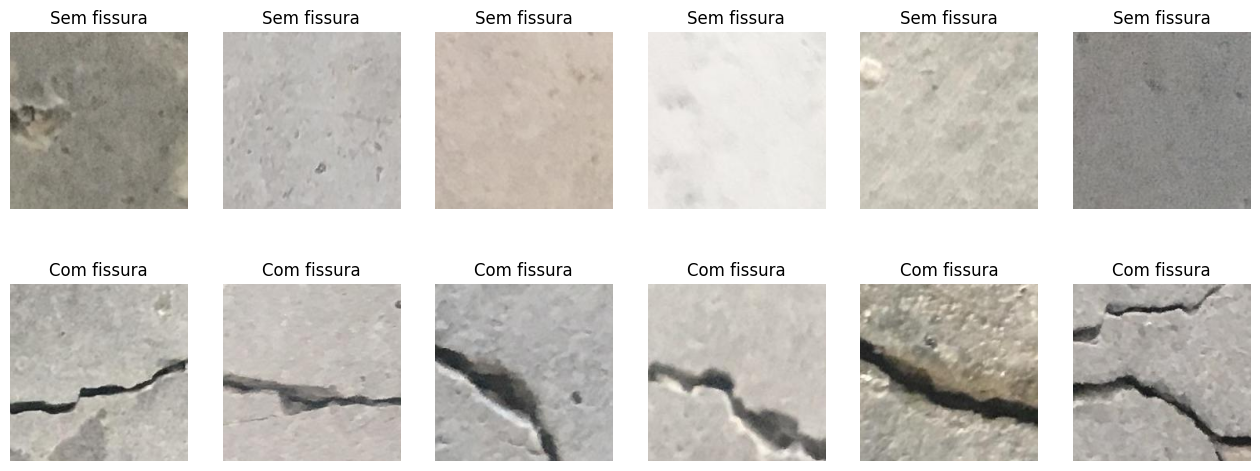

Split (treino / val / teste): 4200 900 900


In [6]:
import random, matplotlib.pyplot as plt, pandas as pd
from sklearn.model_selection import train_test_split
random.seed(42)

# Visualização de amostras das duas classes
fig, axs = plt.subplots(2, 6, figsize=(16, 6))
for r, (pasta, nome) in enumerate([(NEG, 'Sem fissura'), (POS, 'Com fissura')]):
    for ax, f in zip(axs[r], random.sample(os.listdir(f'{BASE}/{pasta}'), 6)):
        ax.imshow(Image.open(f'{BASE}/{pasta}/{f}'))
        ax.set_title(nome)
        ax.axis('off')
plt.show()

# Amostragem balanceada (3000 por classe) e divisão treino/val/teste
N = 3000
rows = []
for label, pasta in [(0, NEG), (1, POS)]:
    for f in random.sample(os.listdir(f'{BASE}/{pasta}'), N):
        rows.append((f'{BASE}/{pasta}/{f}', label))

df = pd.DataFrame(rows, columns=['path', 'label'])
train, temp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp.label, random_state=42)
print('Split (treino / val / teste):', len(train), len(val), len(test))

# Pré-processamento para MobileNetV2
IMG, BS = 224, 32

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)
    return img, tf.cast(label, tf.float32)

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values))
    if shuffle:
        ds = ds.shuffle(len(d), seed=42)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BS).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train, True), make_ds(val), make_ds(test)

In [7]:
from tensorflow.keras import layers, models

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])

hist = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)]
)
model.save('/content/modelo.keras')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 67s 304ms/step - accuracy: 0.9810 - loss: 0.0774 - val_accuracy: 0.9956 - val_loss: 0.0208
Epoch 2/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.9971 - loss: 0.0150 - val_accuracy: 0.9956 - val_loss: 0.0172
Epoch 3/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.9976 - loss: 0.0099 - val_accuracy: 0.9956 - val_loss: 0.0130
Epoch 4/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.9979 - loss: 0.0090 - val_accuracy: 0.9956 - val_loss: 0.0116
Epoch 5/5
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.9988 - loss: 0.0072 - val_accuracy: 0.9956 - val_loss: 0.0107


=== Métricas no Conjunto de Teste (Limiar = 0.5) ===
Acurácia : 0.9967
Precisão : 0.9978
Recall   : 0.9956
F1-Score : 0.9967

              precision    recall  f1-score   support

 Sem fissura     0.9956    0.9978    0.9967       450
 Com fissura     0.9978    0.9956    0.9967       450

    accuracy                         0.9967       900
   macro avg     0.9967    0.9967    0.9967       900
weighted avg     0.9967    0.9967    0.9967       900



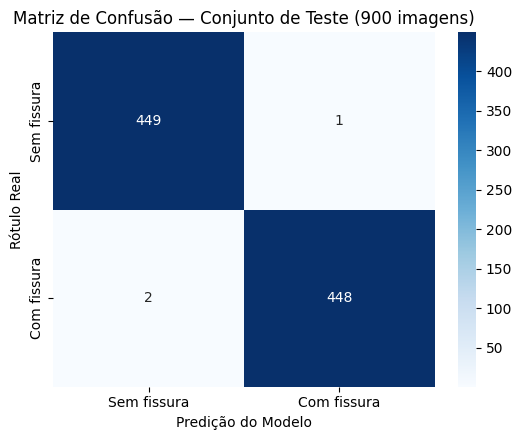

=== Sensibilidade ao Limiar de Confiança ===
Limiar 0.30 | Precisão: 0.9934 | Recall: 0.9978 | F1: 0.9956
Limiar 0.50 | Precisão: 0.9978 | Recall: 0.9956 | F1: 0.9967
Limiar 0.70 | Precisão: 1.0000 | Recall: 0.9933 | F1: 0.9967
Limiar 0.85 | Precisão: 1.0000 | Recall: 0.9822 | F1: 0.9910


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)

LIMIAR = 0.5

# Predições no conjunto de teste (900 imagens)
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= LIMIAR).astype(int)
y_true = test['label'].values

print(f'=== Métricas no Conjunto de Teste (Limiar = {LIMIAR}) ===')
print(f'Acurácia : {accuracy_score(y_true, y_pred):.4f}')
print(f'Precisão : {precision_score(y_true, y_pred):.4f}')
print(f'Recall   : {recall_score(y_true, y_pred):.4f}')
print(f'F1-Score : {f1_score(y_true, y_pred):.4f}\n')
print(classification_report(y_true, y_pred, target_names=['Sem fissura', 'Com fissura'], digits=4))

# Matriz de confusão
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sem fissura', 'Com fissura'],
            yticklabels=['Sem fissura', 'Com fissura'])
plt.xlabel('Predição do Modelo')
plt.ylabel('Rótulo Real')
plt.title('Matriz de Confusão — Conjunto de Teste (900 imagens)')
plt.tight_layout()
plt.savefig('/content/matriz_confusao.png', dpi=150)
plt.show()

# Comparativo rápido de limiares (ajuda a justificar a escolha no relatório)
print('=== Sensibilidade ao Limiar de Confiança ===')
for th in [0.3, 0.5, 0.7, 0.85]:
    yp = (y_prob >= th).astype(int)
    print(f'Limiar {th:.2f} | Precisão: {precision_score(y_true, yp):.4f} | '
          f'Recall: {recall_score(y_true, yp):.4f} | F1: {f1_score(y_true, yp):.4f}')

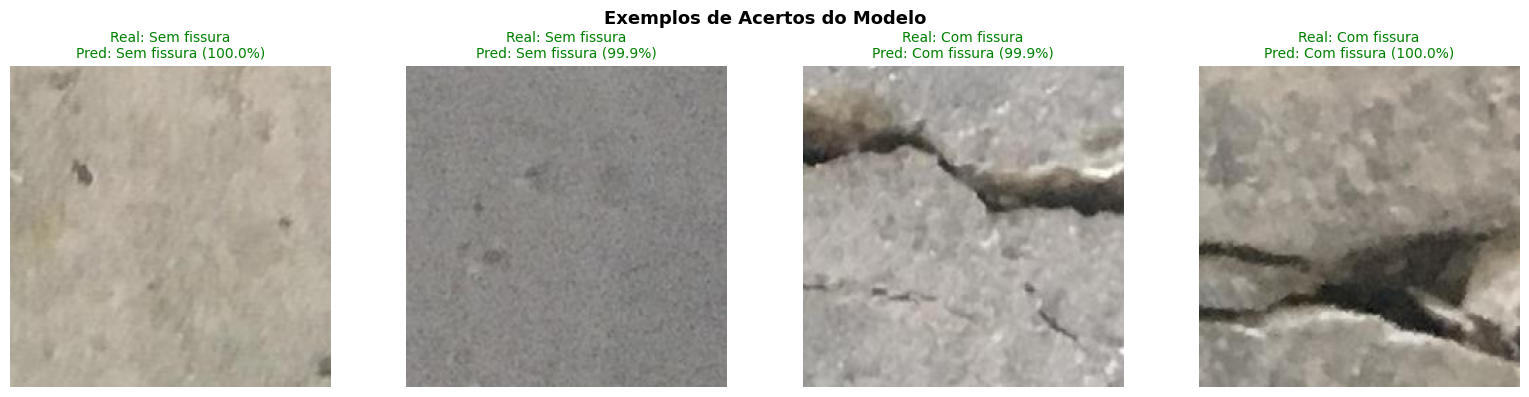

Total de erros no teste: 3 de 900


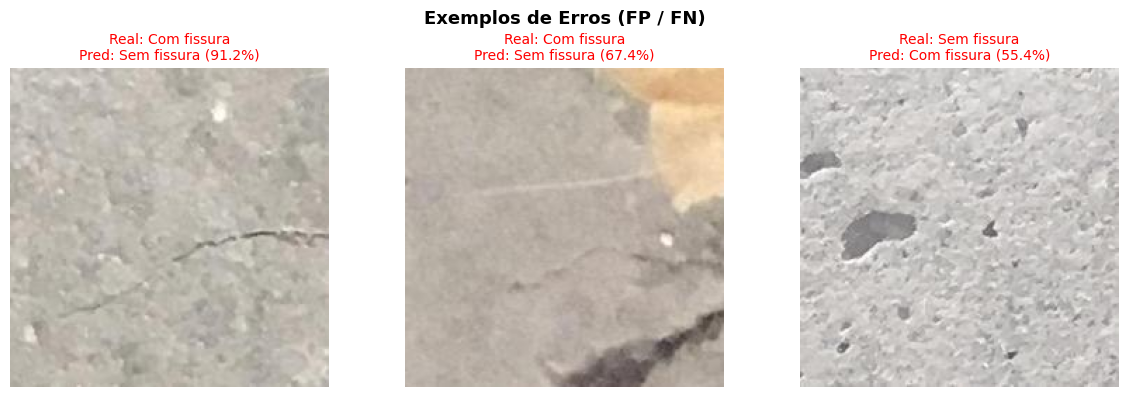

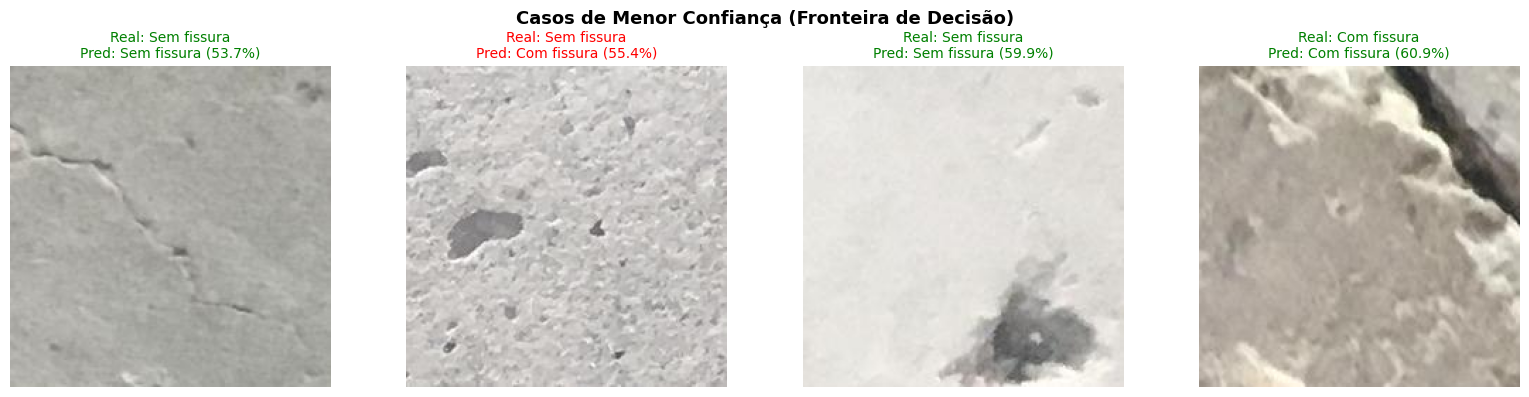

In [9]:
paths_test = test['path'].values
erros_idx = np.where(y_pred != y_true)[0]
acertos_pos = np.where((y_pred == 1) & (y_true == 1))[0]
acertos_neg = np.where((y_pred == 0) & (y_true == 0))[0]

def plotar_grade(indices, titulo, arquivo_saida=None):
    if len(indices) == 0:
        print(f'{titulo}: nenhum caso encontrado.')
        return
    cols = min(4, len(indices))
    rows = int(np.ceil(len(indices) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axs = np.atleast_1d(axs).ravel()
    for ax, idx in zip(axs, indices):
        ax.imshow(Image.open(paths_test[idx]))
        real = 'Com fissura' if y_true[idx] == 1 else 'Sem fissura'
        pred = 'Com fissura' if y_pred[idx] == 1 else 'Sem fissura'
        conf = y_prob[idx] if y_pred[idx] == 1 else (1 - y_prob[idx])
        cor = 'green' if y_true[idx] == y_pred[idx] else 'red'
        ax.set_title(f'Real: {real}\nPred: {pred} ({conf*100:.1f}%)', color=cor, fontsize=10)
        ax.axis('off')
    for ax in axs[len(indices):]:
        ax.axis('off')
    plt.suptitle(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    if arquivo_saida:
        plt.savefig(arquivo_saida, dpi=150)
    plt.show()

# 1. Exemplos de acertos (2 sem fissura + 2 com fissura)
ex_acertos = np.concatenate([acertos_neg[:2], acertos_pos[:2]])
plotar_grade(ex_acertos, 'Exemplos de Acertos do Modelo', '/content/exemplos_acertos.png')

# 2. Exemplos de erros (Falsos Positivos / Falsos Negativos)
print(f'Total de erros no teste: {len(erros_idx)} de {len(y_true)}')
plotar_grade(erros_idx[:8], 'Exemplos de Erros (FP / FN)', '/content/exemplos_erros.png')

# 3. Casos de menor confiança (mais próximos de 0.5 — ótimos para discutir sombras/texturas)
incertos_idx = np.argsort(np.abs(y_prob - 0.5))[:4]
plotar_grade(incertos_idx, 'Casos de Menor Confiança (Fronteira de Decisão)', '/content/casos_incertos.png')

In [10]:
import time

def preprocessar_unica(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)
    return tf.expand_dims(img, axis=0)

# Carrega 100 imagens de teste em memória para medir inferência pura (batch=1)
amostra_paths = paths_test[:100]
tensores = [preprocessar_unica(p) for p in amostra_paths]

# Warm-up (aquece a GPU/grafo do TensorFlow)
for t in tensores[:10]:
    _ = model(t, training=False)

# Medição de inferência pura (batch=1, cenário real de câmera/API)
tempos_inf = []
for t in tensores:
    t0 = time.perf_counter()
    _ = model(t, training=False)
    tempos_inf.append(time.perf_counter() - t0)

# Medição ponta a ponta (leitura + pré-processamento + inferência)
tempos_e2e = []
for p in amostra_paths:
    t0 = time.perf_counter()
    t = preprocessar_unica(p)
    _ = model(t, training=False)
    tempos_e2e.append(time.perf_counter() - t0)

lat_inf_ms = np.mean(tempos_inf) * 1000
fps_inf = 1000.0 / lat_inf_ms
lat_e2e_ms = np.mean(tempos_e2e) * 1000
fps_e2e = 1000.0 / lat_e2e_ms

print('=== Benchmark de Desempenho (Resolução: 224x224 | Batch = 1) ===')
print(f'Inferência pura  -> Latência média: {lat_inf_ms:.2f} ms/img | Throughput: {fps_inf:.1f} FPS')
print(f'Ponta a ponta    -> Latência média: {lat_e2e_ms:.2f} ms/img | Throughput: {fps_e2e:.1f} FPS')

=== Benchmark de Desempenho (Resolução: 224x224 | Batch = 1) ===
Inferência pura  -> Latência média: 167.28 ms/img | Throughput: 6.0 FPS
Ponta a ponta    -> Latência média: 169.66 ms/img | Throughput: 5.9 FPS


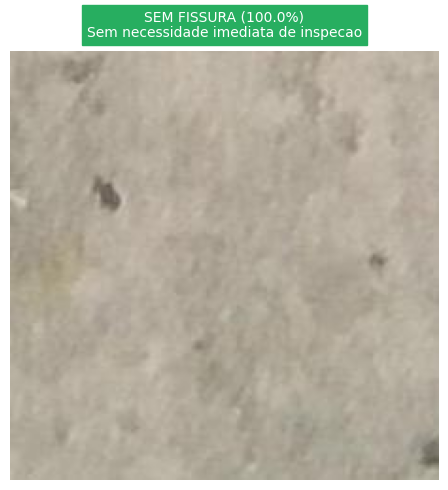

{
  "modulo": "CitizenTech - Visao Computacional (Manutencao Urbana)",
  "arquivo": "17898.jpg",
  "classe": "Sem fissura",
  "confianca": 99.99,
  "probabilidade_fissura": 0.01,
  "acao_sugerida": "Sem necessidade imediata de inspecao",
  "aviso_triagem": "Apoio a triagem visual; nao substitui laudo estrutural.",
  "latencia_ms": 176.17
}
--------------------------------------------------


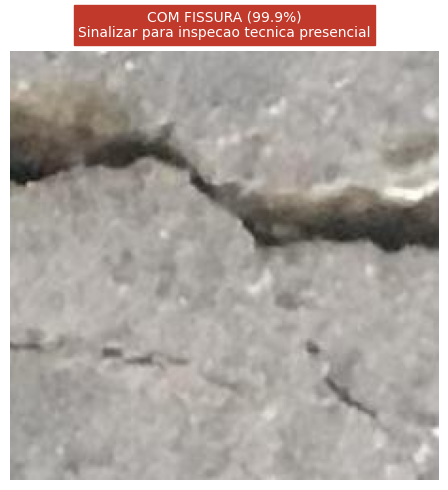

{
  "modulo": "CitizenTech - Visao Computacional (Manutencao Urbana)",
  "arquivo": "01502.jpg",
  "classe": "Com fissura",
  "confianca": 99.87,
  "probabilidade_fissura": 99.87,
  "acao_sugerida": "Sinalizar para inspecao tecnica presencial",
  "aviso_triagem": "Apoio a triagem visual; nao substitui laudo estrutural.",
  "latencia_ms": 164.55
}
--------------------------------------------------


In [11]:
import json

def analisar_imagem_citizentech(caminho_img, limiar=0.5, exibir=True):
    t0 = time.perf_counter()
    x = preprocessar_unica(caminho_img)
    prob_fissura = float(model(x, training=False).numpy()[0][0])
    latencia_ms = (time.perf_counter() - t0) * 1000

    tem_fissura = prob_fissura >= limiar
    confianca = prob_fissura if tem_fissura else (1.0 - prob_fissura)

    resultado = {
        'modulo': 'CitizenTech - Visao Computacional (Manutencao Urbana)',
        'arquivo': os.path.basename(caminho_img),
        'classe': 'Com fissura' if tem_fissura else 'Sem fissura',
        'confianca': round(confianca * 100, 2),
        'probabilidade_fissura': round(prob_fissura * 100, 2),
        'acao_sugerida': 'Sinalizar para inspecao tecnica presencial' if tem_fissura else 'Sem necessidade imediata de inspecao',
        'aviso_triagem': 'Apoio a triagem visual; nao substitui laudo estrutural.',
        'latencia_ms': round(latencia_ms, 2)
    }

    if exibir:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(Image.open(caminho_img))
        cor = '#c0392b' if tem_fissura else '#27ae60'
        titulo = f"{resultado['classe'].upper()} ({resultado['confianca']:.1f}%)\n{resultado['acao_sugerida']}"
        ax.set_title(titulo, color='white', backgroundcolor=cor, fontsize=10, pad=10)
        ax.axis('off')
        plt.tight_layout()
        plt.show()

    return resultado

# Demonstração com 1 imagem sem fissura e 1 com fissura do conjunto de teste
for idx in [acertos_neg[0], acertos_pos[0]]:
    res = analisar_imagem_citizentech(paths_test[idx], limiar=0.5)
    print(json.dumps(res, indent=2, ensure_ascii=False))
    print('-' * 50)

Vídeo gerado com sucesso: /content/monitoramento_citizentech.mp4
Quadros processados: 30 | Alertas de fissura: 15
Latência média no vídeo: 188.72 ms/quadro | 5.3 FPS


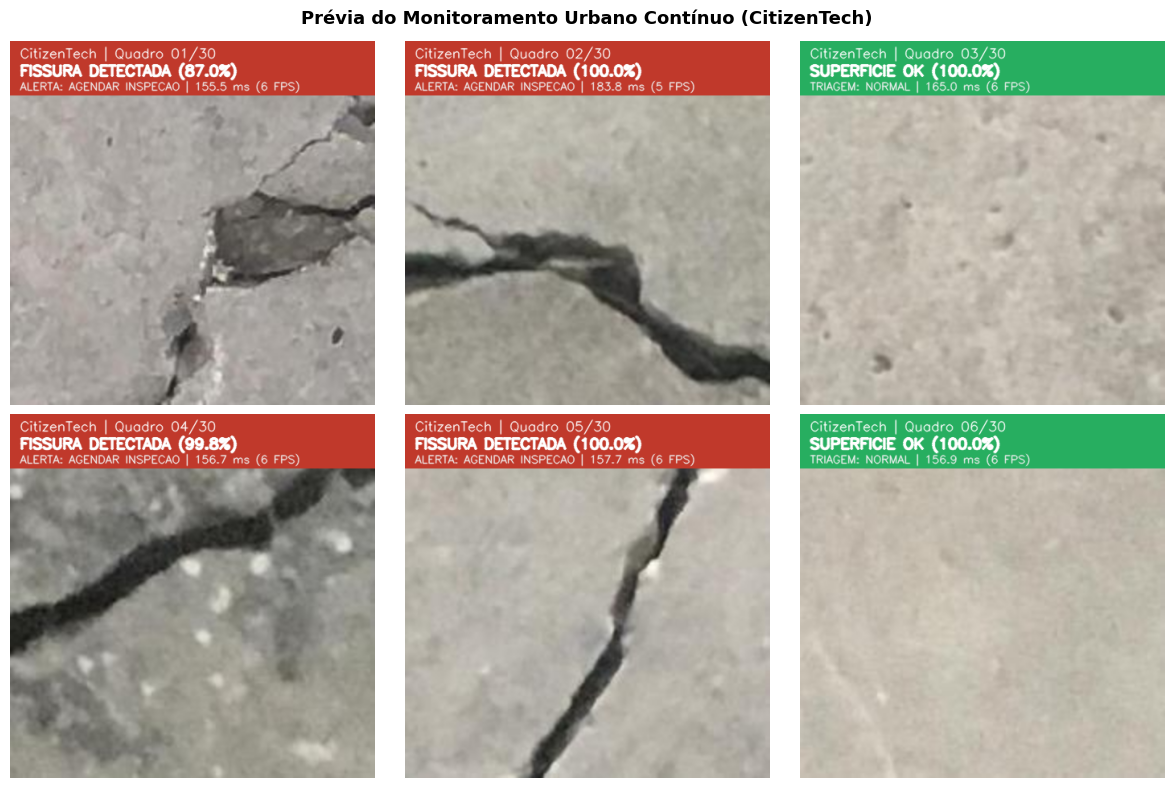

In [12]:
import cv2

# Seleciona 15 imagens sem fissura e 15 com fissura do teste e embaralha
rng = np.random.default_rng(42)
seq_idx = np.concatenate([
    rng.choice(np.where(y_true == 0)[0], 15, replace=False),
    rng.choice(np.where(y_true == 1)[0], 15, replace=False)
])
rng.shuffle(seq_idx)

VIDEO_OUT = '/content/monitoramento_citizentech.mp4'
FPS_VIDEO = 2  # 2 quadros/seg -> 15 segundos de vídeo fácil de visualizar
W, H = 454, 454

writer = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*'mp4v'), FPS_VIDEO, (W, H))

alertas = 0
tempos_frame = []
frames_preview = []

for i, idx in enumerate(seq_idx, start=1):
    frame_bgr = cv2.imread(paths_test[idx])
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    # Inferência no quadro
    t0 = time.perf_counter()
    inp = tf.image.resize(frame_rgb, (IMG, IMG))
    inp = tf.keras.applications.mobilenet_v2.preprocess_input(inp)
    prob = float(model(tf.expand_dims(inp, 0), training=False).numpy()[0][0])
    dt = time.perf_counter() - t0
    tempos_frame.append(dt)

    tem_fissura = prob >= LIMIAR
    conf = prob if tem_fissura else (1.0 - prob)
    if tem_fissura:
        alertas += 1

    # Desenha HUD CitizenTech no quadro
    vis = cv2.resize(frame_bgr, (W, H))
    cor_bgr = (43, 57, 192) if tem_fissura else (96, 174, 39)
    status = f"FISSURA DETECTADA ({conf*100:.1f}%)" if tem_fissura else f"SUPERFICIE OK ({conf*100:.1f}%)"
    acao = "ALERTA: AGENDAR INSPECAO" if tem_fissura else "TRIAGEM: NORMAL"

    cv2.rectangle(vis, (0, 0), (W, 68), cor_bgr, -1)
    cv2.putText(vis, f"CitizenTech | Quadro {i:02d}/{len(seq_idx)}", (12, 22),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(vis, status, (12, 44),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(vis, f"{acao} | {dt*1000:.1f} ms ({1/dt:.0f} FPS)", (12, 62),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (240, 240, 240), 1, cv2.LINE_AA)

    writer.write(vis)
    if len(frames_preview) < 6:
        frames_preview.append(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))

writer.release()

print(f'Vídeo gerado com sucesso: {VIDEO_OUT}')
print(f'Quadros processados: {len(seq_idx)} | Alertas de fissura: {alertas}')
print(f'Latência média no vídeo: {np.mean(tempos_frame)*1000:.2f} ms/quadro | {1/np.mean(tempos_frame):.1f} FPS')

# Mostra uma prévia de 6 quadros direto no notebook
fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for ax, fr in zip(axs.ravel(), frames_preview):
    ax.imshow(fr)
    ax.axis('off')
plt.suptitle('Prévia do Monitoramento Urbano Contínuo (CitizenTech)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/preview_video.png', dpi=150)
plt.show()